\# Agrégation spatiale : IRIS et Bureaux de vote
> Pondération par surface d'intersection

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

BASE    = "/content/drive/MyDrive/Stage/Agreation_Bureau_Socio/"
GEOJSON = "/content/drive/MyDrive/Stage/geojson/contours_france_entiere.geojson"


Mounted at /content/drive


## 1. Chargement des données

In [2]:
# Voronoï
bureaux = gpd.read_file(GEOJSON)
print(f" Voronoï : {len(bureaux):,} bureaux | CRS : {bureaux.crs}")

#  Contours IRIS IGN
iris_geo = gpd.read_file(BASE + "CONTOURS-IRIS_2-1_SHP_LAMB93_FXX-2022/CONTOURS-IRIS.shp")
iris_geo["CODE_IRIS"] = iris_geo["CODE_IRIS"].astype(str).str.zfill(9)
print(f" IRIS géo : {len(iris_geo):,} IRIS | CRS : {iris_geo.crs.to_epsg()}")

#  Base socio
iris_data = pd.read_csv(BASE + "iris_socio_final.csv", sep=",", dtype={"IRIS": str})
iris_data["IRIS"] = iris_data["IRIS"].str.zfill(9)
print(f" IRIS socio : {len(iris_data):,} IRIS | {len(iris_data.columns)} variables")
print(f"  Exemple IRIS : {iris_data['IRIS'].iloc[0]}")

#  Résultats électoraux
elec = pd.read_csv(
    "/content/drive/MyDrive/Stage/resultats_t1_bureaux_clusters_K5.csv",
    dtype={"id_bv": str}, low_memory=False
)
print(f" Électoral : {len(elec):,} bureaux | Exemple : {elec['id_bv'].iloc[0]}")

 Voronoï : 68,806 bureaux | CRS : EPSG:4326
 IRIS géo : 48,580 IRIS | CRS : 2154
 IRIS socio : 48,046 IRIS | 19 variables
  Exemple IRIS : 010010000
 Électoral : 68,770 bureaux | Exemple : 01_001_0001


## 2. Jointure géographique + socio-économique

In [3]:
# Jointure géo × socio
iris = iris_geo.merge(iris_data, left_on="CODE_IRIS", right_on="IRIS", how="inner")

# Nettoyage colonnes dupliquées
iris = iris.drop(columns=["IRIS_x","IRIS_y","NOM_IRIS","COM","TYP_IRIS_y"], errors="ignore")
iris = iris.rename(columns={"CODE_IRIS":"IRIS", "TYP_IRIS_x":"TYP_IRIS"})

print(f" IRIS avec données geo+socio : {len(iris):,}")
print(f"  IRIS géo sans match socio   : {len(iris_geo) - len(iris):,} (types A/D exclus)")

# Reprojection Lambert 93 pour calculs de surface métriques
bureaux_proj = bureaux.to_crs("EPSG:2154")
iris_proj    = iris.to_crs("EPSG:2154")

print(f" CRS harmonisés : {bureaux_proj.crs.to_epsg()} = {iris_proj.crs.to_epsg()}")

# Surface des bureaux en m²
bureaux_proj["area_bureau"] = bureaux_proj.geometry.area
print(f"  Surface bureaux : min:{bureaux_proj['area_bureau'].min():,.0f} m² "
      f"max:{bureaux_proj['area_bureau'].max():,.0f} m² "
      f"moy:{bureaux_proj['area_bureau'].mean():,.0f} m²")

 IRIS avec données geo+socio : 47,407
  IRIS géo sans match socio   : 1,173 (types A/D exclus)
 CRS harmonisés : 2154 = 2154
  Surface bureaux : min:200 m² max:18,590,208,351 m² moy:9,789,749 m²


## 3. Intersection spatiale Voronoï × IRIS

In [4]:

intersection = gpd.overlay(
    bureaux_proj[["id_bv","area_bureau","geometry"]],
    iris_proj,
    how="intersection",
    keep_geom_type=False
)

print(f" Intersection : {len(intersection):,} fragments")
print(f"  Colonnes : {intersection.columns.tolist()}")

 Intersection : 375,811 fragments
  Colonnes : ['id_bv', 'area_bureau', 'INSEE_COM', 'NOM_COM', 'IRIS', 'TYP_IRIS', 'DEP', 'P22_POP1564', 'P22_ACT1564', 'taux_chomage', 'taux_emploi', 'part_voiture', 'part_tcom', 'part_diplmin', 'part_bac2', 'part_bac34', 'part_bac5plus', 'DISP_MED21', 'taux_pauvrete', 'ratio_d9_d1', 'd1_revenu', 'd9_revenu', 'geometry']


In [5]:
intersection.head()

,id_bv,area_bureau,INSEE_COM,NOM_COM,IRIS,TYP_IRIS,DEP,P22_POP1564,P22_ACT1564,taux_chomage,...,part_diplmin,part_bac2,part_bac34,part_bac5plus,DISP_MED21,taux_pauvrete,ratio_d9_d1,d1_revenu,d9_revenu,geometry
0,01001_1,1.561999e+07,01028,Baneins,010280000,Z,01,358.206089,291.811774,0.040227,...,0.092062,0.145372,0.104546,0.067925,25520.0,17.0,3.2,12790.0,38370.0,"MULTIPOLYGON (((848710.668 6559617.76, 848580...."
1,01001_1,1.561999e+07,01001,L'Abergement-Clémenciat,010010000,Z,01,525.000000,431.000000,0.064965,...,0.081206,0.174014,0.120650,0.076566,25820.0,17.0,3.2,12790.0,38370.0,"POLYGON ((851076.703 6563324.306, 851076.432 6..."
2,01001_1,1.561999e+07,01093,Châtillon-sur-Chalaronne,010930000,Z,01,2897.583051,2280.312965,0.088400,...,0.088337,0.158259,0.122201,0.096888,23430.0,10.0,2.8,13920.0,38660.0,"MULTIPOLYGON (((851066.118 6563309.047, 851034..."
3,01001_1,1.561999e+07,01351,Saint-Étienne-sur-Chalaronne,013510000,Z,01,1002.211750,792.036907,0.050440,...,0.076349,0.160693,0.124965,0.067780,23960.0,17.0,3.2,12790.0,38370.0,"MULTIPOLYGON (((846825.465 6563787.448, 846835..."
4,01001_1,1.561999e+07,01412,Sulignat,014120000,Z,01,385.994156,315.905958,0.057563,...,0.069571,0.179910,0.092676,0.082260,24630.0,17.0,3.2,12790.0,38370.0,"MULTIPOLYGON (((849080.331 6566670.979, 849068..."


## 4. Calcul et normalisation des poids

In [6]:
# Surface d'intersection et poids bruts
intersection["area_intersection"] = intersection.geometry.area
intersection["poids"] = intersection["area_intersection"] / intersection["area_bureau"]

# Vérification avant normalisation
poids_sum = intersection.groupby("id_bv")["poids"].sum()
print(f"Poids bruts  min:{poids_sum.min():.4f} max:{poids_sum.max():.4f} "
      f"moy:{poids_sum.mean():.4f}")
print(f"Bureaux avec poids < 0.95 : {(poids_sum < 0.95).sum():,}")

# Normalisation
intersection["poids"] = intersection.groupby("id_bv")["poids"].transform(
    lambda x: x / x.sum() if x.sum() > 0 else x
)

poids_norm = intersection.groupby("id_bv")["poids"].sum()
print(f"\nAprès normalisation  min:{poids_norm.min():.4f} max:{poids_norm.max():.4f} "
      f"moy:{poids_norm.mean():.4f}")
print(f"Bureaux != 1.0 : {((poids_norm - 1.0).abs() > 0.001).sum()}")

Poids bruts  min:0.0000 max:1.0000 moy:0.9758
Bureaux avec poids < 0.95 : 3,563

Après normalisation  min:1.0000 max:1.0000 moy:1.0000
Bureaux != 1.0 : 0


In [7]:
# Surface d'intersection
intersection["area_intersection"] = intersection.geometry.area

# Surface de chaque IRIS
iris_proj["area_iris"] = iris_proj.geometry.area
intersection = intersection.merge(
    iris_proj[["IRIS","area_iris"]], on="IRIS", how="left"
)

# poids = part de l'IRIS qui va dans ce bureau
intersection["poids_iris"] = (
    intersection["area_intersection"] / intersection["area_iris"]
)

# Attribution du nombre d'individus de l'IRIS qui revient à ce bureau
intersection["individus_attribues"] = (
    intersection["poids_iris"] * intersection["P22_ACT1564"]
)

# Vérification : la somme des poids_iris pour un même IRIS (sur tous les
# bureaux qui l'intersectent) doit faire 1.0
poids_iris_sum = intersection.groupby("IRIS")["poids_iris"].sum()
print(f"Poids_iris (somme par IRIS)  min:{poids_iris_sum.min():.4f} "
      f"max:{poids_iris_sum.max():.4f} moy:{poids_iris_sum.mean():.4f}")
print(f"IRIS avec somme < 0.95 : {(poids_iris_sum < 0.95).sum():,}")

# Normalisation par IRIS (et non plus par bureau !)
intersection["poids_iris"] = intersection.groupby("IRIS")["poids_iris"].transform(
    lambda x: x / x.sum() if x.sum() > 0 else x
)
intersection["individus_attribues"] = (
    intersection["poids_iris"] * intersection["P22_ACT1564"]
)

#  Poids final pour l'agrégation au niveau bureau esr égal à la
#  part des individus du bureau qui viennent de cet IRIS
intersection["poids"] = intersection.groupby("id_bv")["individus_attribues"].transform(
    lambda x: x / x.sum() if x.sum() > 0 else x
)

poids_norm = intersection.groupby("id_bv")["poids"].sum()
print(f"\nPoids final par bureau — min:{poids_norm.min():.4f} "
      f"max:{poids_norm.max():.4f} moy:{poids_norm.mean():.4f}")

Poids_iris (somme par IRIS)  min:0.5829 max:1.4319 moy:0.9999
IRIS avec somme < 0.95 : 24

Poids final par bureau — min:1.0000 max:1.0000 moy:1.0000


## 5. Agrégation pondérée

In [8]:
vars_socio = [
    "P22_POP1564","P22_ACT1564",
    "taux_chomage","taux_emploi",
    "part_voiture","part_tcom",
    "part_diplmin","part_bac2","part_bac34","part_bac5plus",
    "DISP_MED21","taux_pauvrete","ratio_d9_d1","d1_revenu","d9_revenu"
]
vars_dispo = [v for v in vars_socio if v in intersection.columns]
print(f"Variables à agréger : {len(vars_dispo)}")

# Agrégation pondérée : V(bureau) = Σ poids_i × V(IRIS_i)

for var in vars_dispo:
    intersection[f"{var}_pond"] = intersection[var] * intersection["poids"]

cols_pond = [f"{v}_pond" for v in vars_dispo]
result = intersection.groupby("id_bv")[cols_pond].sum().reset_index()
result = result.rename(columns={f"{v}_pond": v for v in vars_dispo})

print(f" Agrégation terminée : {len(result):,} bureaux × {len(vars_dispo)} variables")
result.head(3)

Variables à agréger : 15
 Agrégation terminée : 66,815 bureaux × 15 variables


,id_bv,P22_POP1564,P22_ACT1564,taux_chomage,taux_emploi,part_voiture,part_tcom,part_diplmin,part_bac2,part_bac34,part_bac5plus,DISP_MED21,taux_pauvrete,ratio_d9_d1,d1_revenu,d9_revenu
0,01001_1,547.678776,448.576964,0.065124,0.934876,0.921243,0.011515,0.081249,0.173739,0.120440,0.076660,25786.167805,16.928895,3.195937,12801.478387,38372.945781
1,01002_1,195.430863,156.415402,0.017442,0.982558,0.911441,0.043254,0.039369,0.201895,0.185671,0.134096,24449.215090,16.955311,3.193503,12793.752855,38337.996542
2,01004_1,1920.970032,1469.061805,0.108629,0.891371,0.697927,0.119910,0.147971,0.147154,0.086937,0.102514,20778.811713,17.000000,3.099997,11890.831888,36451.170196


In [9]:
#Agrégation pondérée par INDIVIDUS
# poids_pop_i = Pop(IRIS_i) × Aire(b ∩ IRIS_i)/ Σ_j [Pop(IRIS_j) × Aire(b ∩ IRIS_j)]

intersection["poids_pop"] = (
    intersection["area_intersection"] * intersection["P22_POP1564"]
)
intersection["poids_pop"] = intersection.groupby("id_bv")["poids_pop"].transform(
    lambda x: x / x.sum() if x.sum() > 0 else x
)

# Vérification
poids_pop_sum = intersection.groupby("id_bv")["poids_pop"].sum()
print(f"Poids pop — min:{poids_pop_sum.min():.4f} max:{poids_pop_sum.max():.4f}")

# Agrégation
for var in vars_dispo:
    intersection[f"{var}_pond_pop"] = intersection[var] * intersection["poids_pop"]

cols_pond_pop = [f"{v}_pond_pop" for v in vars_dispo]
result_pop = intersection.groupby("id_bv")[cols_pond_pop].sum().reset_index()
result_pop = result_pop.rename(columns={f"{v}_pond_pop": v for v in vars_dispo})

print(f" Agrégation par individus : {len(result_pop):,} bureaux × {len(vars_dispo)} variables")
vars_socio_prof = [
    "taux_chomage","part_voiture","part_tcom",
    "part_diplmin","part_bac2","part_bac34","part_bac5plus",
    "DISP_MED21","P22_POP1564","P22_ACT1564"
]
# Comparaison surface vs individus sur les bureaux de Lyon
for bv in ["69381_109", "69381_117"]:
    print(f"\n Bureau {bv} ")
    print(f"{'Variable':<25} {'Surface':>12} {'Individus':>12} {'Diff':>10}")
    print("-" * 62)

    r_surf = result[result["id_bv"] == bv]
    r_pop  = result_pop[result_pop["id_bv"] == bv]

    for var in vars_socio_prof :
        v_surf = r_surf[var].values[0] if len(r_surf) > 0 else float('nan')
        v_pop  = r_pop[var].values[0]  if len(r_pop)  > 0 else float('nan')
        diff   = v_pop - v_surf
        print(f"  {var:<23} {v_surf:>12.4f} {v_pop:>12.4f} {diff:>+10.4f}")



Poids pop — min:1.0000 max:1.0000
 Agrégation par individus : 66,815 bureaux × 15 variables

 Bureau 69381_109 
Variable                       Surface    Individus       Diff
--------------------------------------------------------------
  taux_chomage                  0.1380       0.1367    -0.0013
  part_voiture                  0.1178       0.1159    -0.0019
  part_tcom                     0.4559       0.4503    -0.0056
  part_diplmin                  0.0455       0.0444    -0.0011
  part_bac2                     0.1123       0.1133    +0.0010
  part_bac34                    0.1909       0.1944    +0.0035
  part_bac5plus                 0.4366       0.4360    -0.0007
  DISP_MED21                23289.1723   23667.3359  +378.1636
  P22_POP1564                2818.9028    2975.0247  +156.1219
  P22_ACT1564                2216.3500    2330.0893  +113.7392

 Bureau 69381_117 
Variable                       Surface    Individus       Diff
-------------------------------------------------

In [10]:

if "area_iris" not in intersection.columns:
    iris_proj["area_iris"] = iris_proj.geometry.area
    intersection = intersection.merge(
        iris_proj[["IRIS","area_iris"]], on="IRIS", how="left"
    )


## 6. Fallback pour bureaux non couverts

In [11]:
def extract_dep(id_bv):
    code = id_bv.split("_")[0]
    if code.startswith("97"): return code[:3]
    elif code.startswith("2A") or code.startswith("2B"): return code[:2]
    else: return code[:2]

# Identifier bureaux peu fiables (poids bruts < 0.10 = géométrie incohérente)
poids_bruts = intersection.copy()
poids_bruts["poids_brut"] = poids_bruts["area_intersection"] / poids_bruts["area_bureau"]
poids_bruts_sum = poids_bruts.groupby("id_bv")["poids_brut"].sum()

bv_fiables    = poids_bruts_sum[poids_bruts_sum >= 0.10].index
bv_peu_fiable = poids_bruts_sum[poids_bruts_sum <  0.10].index
print(f"Bureaux fiables     : {len(bv_fiables):,}")
print(f"Bureaux peu fiables : {len(bv_peu_fiable):,}")

# Moyenne par département depuis bureaux fiables
result_fiables = result[result["id_bv"].isin(bv_fiables)].copy()
result_fiables["dep"] = result_fiables["id_bv"].apply(extract_dep)
dep_moy = result_fiables.groupby("dep")[vars_dispo].mean().reset_index()

# Bureaux à remplacer : peu fiables + manquants
bv_manquants = list(set(bureaux["id_bv"]) - set(result["id_bv"]))
bv_fallback  = list(bv_peu_fiable) + bv_manquants
print(f"Bureaux avec fallback département : {len(bv_fallback):,}")

fallback_df = pd.DataFrame({"id_bv": bv_fallback})
fallback_df["dep"] = fallback_df["id_bv"].apply(extract_dep)
fallback_df = fallback_df.merge(dep_moy, on="dep", how="left").drop(columns=["dep"])

# Assemblage
result_complet = pd.concat(
    [result_fiables.drop(columns=["dep"]), fallback_df],
    ignore_index=True
)
print(f"\n result_complet : {len(result_complet):,} bureaux")

# Fallback national pour NaN restants (DOM sans données)
nan_mask = result_complet[vars_dispo[0]].isna()
if nan_mask.sum() > 0:
    moy_nat = result_fiables[vars_dispo].mean()
    for var in vars_dispo:
        result_complet[var] = result_complet[var].fillna(moy_nat[var])

print(f"  NaN restants : {result_complet[vars_dispo[0]].isna().sum()}")
print(f"  Couverture   : {len(result_complet)/len(bureaux)*100:.1f}%")

Bureaux fiables     : 66,523
Bureaux peu fiables : 292
Bureaux avec fallback département : 2,283

 result_complet : 68,806 bureaux
  NaN restants : 0
  Couverture   : 100.0%


## 7. Vérification statistique

STATISTIQUES DES VARIABLES AGRÉGÉES PAR BUREAU
  P22_POP1564               moy= 1206.709  min=    3.627  max= 9547.879  NaN=0
  P22_ACT1564               moy=  914.802  min=    1.594  max= 7939.343  NaN=0
  taux_chomage              moy=    0.106  min=    0.000  max=    0.951  NaN=0
  taux_emploi               moy=    0.894  min=    0.049  max=    1.000  NaN=0
  part_voiture              moy=    0.766  min=    0.000  max=    1.000  NaN=0
  part_tcom                 moy=    0.093  min=    0.000  max=    0.991  NaN=0
  part_diplmin              moy=    0.089  min=    0.000  max=    0.978  NaN=0
  part_bac2                 moy=    0.149  min=    0.000  max=    0.827  NaN=0
  part_bac34                moy=    0.117  min=    0.000  max=    0.475  NaN=0
  part_bac5plus             moy=    0.127  min=    0.000  max=    0.721  NaN=0
  DISP_MED21                moy=23407.083  min=11071.481  max=64676.464  NaN=0
  taux_pauvrete             moy=   14.932  min=    5.000  max=   52.000  NaN=0
  rat

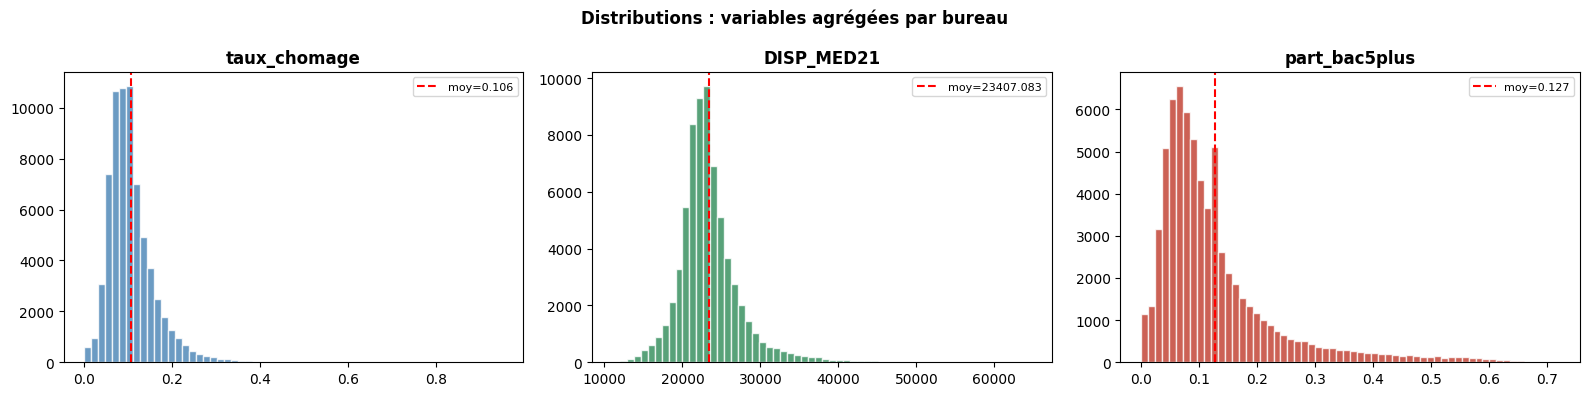

In [12]:
print("=" * 62)
print("STATISTIQUES DES VARIABLES AGRÉGÉES PAR BUREAU")
print("=" * 62)
for var in vars_dispo:
    m = result_complet[var].mean()
    mn= result_complet[var].min()
    mx= result_complet[var].max()
    n = result_complet[var].isna().sum()
    print(f"  {var:<25} moy={m:>9.3f}  min={mn:>9.3f}  max={mx:>9.3f}  NaN={n}")

# Histogrammes
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, var, color in zip(axes,
    ["taux_chomage","DISP_MED21","part_bac5plus"],
    ["steelblue","#2E8B57","#C0392B"]):
    data = result_complet[var].dropna()
    ax.hist(data, bins=60, color=color, edgecolor='white', alpha=0.8)
    ax.axvline(data.mean(), color='red', linestyle='--',
               label=f'moy={data.mean():.3f}')
    ax.set_title(var, fontweight='bold')
    ax.legend(fontsize=8)
plt.suptitle("Distributions : variables agrégées par bureau", fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Harmonisation des identifiants bureaux

In [13]:
def convert_id_bv_final(id_bv, voronoi_set=None):
    """
    Convertit l'id_bv du fichier électoral vers le format Voronoï.
    Si le format standard ne matche pas et que voronoi_set est fourni,
    essaie plusieurs variantes de zfill avant d'abandonner.
    """
    parts      = id_bv.split("_")
    dep        = parts[0]
    commune    = parts[1]
    bureau_str = parts[2]

    # Grandes villes avec arrondissements
    if (dep, commune) in [("75","056"), ("69","123"), ("13","055")]:
        if bureau_str.isdigit() and len(bureau_str) == 4:
            arr = int(bureau_str[:2])
            bur = int(bureau_str[2:])
            if dep == "75":
                return f"751{arr:02d}_{bur}"
            elif dep == "69":
                return f"6938{arr}_{arr}{bur:02d}"
            else:
                return f"132{arr:02d}_{arr}{bur:02d}"
        else:
            return f"{dep}{commune}_{bureau_str}"

    #  DOM
    if len(dep) == 3 and dep.startswith("97"):
        commune_court = commune[1:]
        return f"{dep}{commune_court}_{int(bureau_str)}"

    #  Bureau numérique : tester plusieurs formats si nécessaire
    if bureau_str.replace(".","").isdigit():
        bureau_num = int(float(bureau_str))
        standard = f"{dep}{commune}_{bureau_num}"

        # Si pas de set fourni, ou si le standard matche déjà, on s'arrête là
        if voronoi_set is None or standard in voronoi_set:
            return standard

        # Sinon, essayer les variantes (zfill2/3/4, avec espace)
        candidats = [
            f"{dep}{commune}_{bureau_num:02d}",
            f"{dep}{commune}_{bureau_num:03d}",
            f"{dep}{commune}_{bureau_num:04d}",
            f"{dep}{commune}_{bureau_num} ",
            f"{dep}{commune}_{bureau_num:02d} ",
            f"{dep}{commune}_{bureau_num:03d} ",
        ]
        for c in candidats:
            if c in voronoi_set:
                return c
        return standard  # rien trouvé, retourner le standard (ira au fallback dép)

    #  Avec lettre "0A11" → "A11"
    if not bureau_str.isdigit():
        bureau = bureau_str.lstrip("0") or bureau_str
        return f"{dep}{commune}_{bureau}"

    return f"{dep}{commune}_{bureau_str}"

## 9. Jointure électorale + socio

In [14]:
# Appel avec le set Voronoï pour activer le fallback multi-format
voronoi_set = set(bureaux["id_bv"])
elec["id_bv_voronoi"] = elec["id_bv"].apply(lambda x: convert_id_bv_final(x, voronoi_set))

match     = set(elec["id_bv_voronoi"]) & set(result_complet["id_bv"])
non_match = elec[~elec["id_bv_voronoi"].isin(result_complet["id_bv"])]
print(f"Codes en commun : {len(match):,}")
print(f"Non matchés     : {len(non_match):,}")

Codes en commun : 67,882
Non matchés     : 888


In [15]:
# Jointure finale
base_finale = elec.merge(
    result_complet,
    left_on="id_bv_voronoi",
    right_on="id_bv",
    how="left"
)
# Nettoyage colonnes id_bv dupliquées
base_finale = base_finale.drop(columns=["id_bv_y"], errors="ignore")
base_finale = base_finale.rename(columns={"id_bv_x": "id_bv"})

nan_apres = base_finale["taux_chomage"].isna().sum()
print(f"✓ Base finale : {len(base_finale):,} bureaux × {len(base_finale.columns)} colonnes")
print(f"  NaN taux_chomage : {nan_apres:,}")

✓ Base finale : 68,770 bureaux × 45 colonnes
  NaN taux_chomage : 888


In [16]:
# Fallback département pour les non matchés
nan_mask = base_finale["taux_chomage"].isna()
if nan_mask.sum() > 0:
    base_finale["dep_temp"] = base_finale["id_bv"].apply(
        lambda x: x.split("_")[0][:2]
    )
    dep_moy_elec = (
        base_finale[~nan_mask]
        .groupby("dep_temp")[vars_dispo].mean()
        .reset_index()
    )
    base_finale = base_finale.merge(
        dep_moy_elec, on="dep_temp", how="left", suffixes=("","_dep")
    )
    for var in vars_dispo:
        col_dep = f"{var}_dep"
        if col_dep in base_finale.columns:
            base_finale[var] = base_finale[var].fillna(base_finale[col_dep])
            base_finale = base_finale.drop(columns=[col_dep])
    base_finale = base_finale.drop(columns=["dep_temp"])
    print(f"Après fallback département : {base_finale['taux_chomage'].isna().sum()} NaN")

# Fallback national pour NaN restants
nan_mask2 = base_finale["taux_chomage"].isna()
if nan_mask2.sum() > 0:
    moy_nat2 = base_finale[~nan_mask2][vars_dispo].mean()
    for var in vars_dispo:
        base_finale[var] = base_finale[var].fillna(moy_nat2[var])
    print(f"Après fallback national    : {base_finale['taux_chomage'].isna().sum()} NaN")

print(f"\n NaN final : {base_finale['taux_chomage'].isna().sum()}")
print(f"  Bureaux total : {len(base_finale):,}")

Après fallback département : 0 NaN

 NaN final : 0
  Bureaux total : 68,770


## 10. Premières corrélations socio-vote

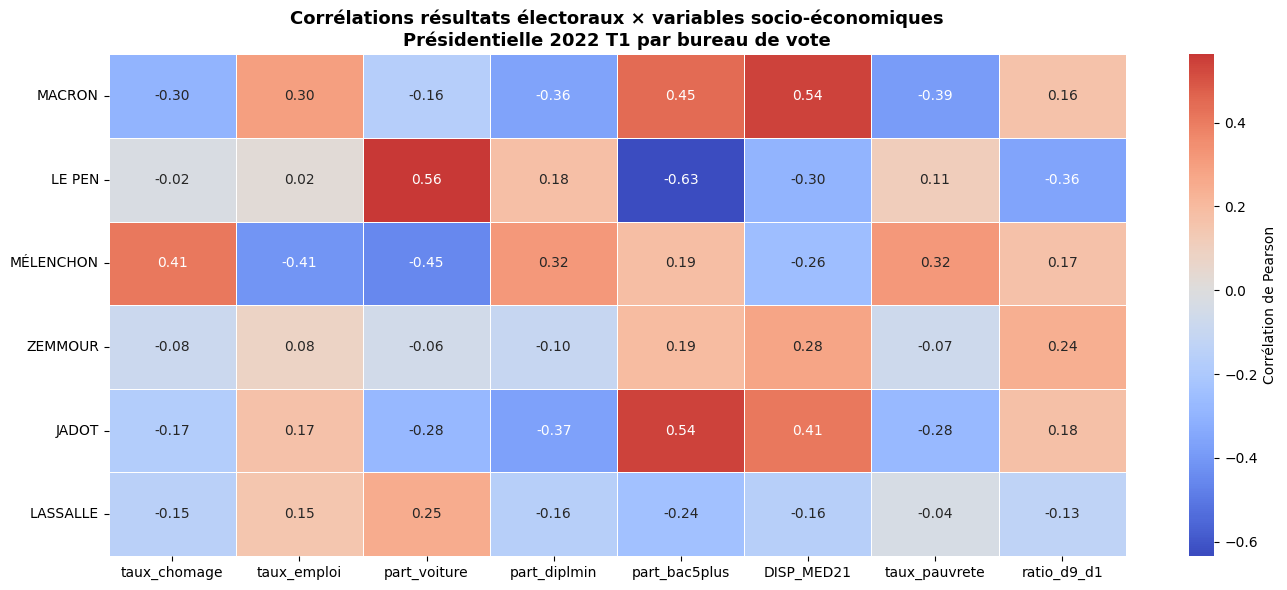


 Corrélations les plus fortes par candidat 
  MACRON       → DISP_MED21           r = +0.540
  LE PEN       → part_bac5plus        r = -0.635
  MÉLENCHON    → part_voiture         r = -0.450
  ZEMMOUR      → DISP_MED21           r = +0.279
  JADOT        → part_bac5plus        r = +0.544
  LASSALLE     → part_voiture         r = +0.251


In [17]:
CANDS_COURT = {
    "MACRON_Emmanuel":    "MACRON",
    "LE PEN_Marine":      "LE PEN",
    "MÉLENCHON_Jean-Luc": "MÉLENCHON",
    "ZEMMOUR_Éric":       "ZEMMOUR",
    "JADOT_Yannick":      "JADOT",
    "LASSALLE_Jean":      "LASSALLE",
}
vars_socio_corr = [
    "taux_chomage","taux_emploi","part_voiture",
    "part_diplmin","part_bac5plus",
    "DISP_MED21","taux_pauvrete","ratio_d9_d1"
]
cands_dispo  = [c for c in CANDS_COURT if c in base_finale.columns]
vars_dispo_c = [v for v in vars_socio_corr if v in base_finale.columns]

# Matrice de corrélation vote × socio
corr_mat  = base_finale[cands_dispo + vars_dispo_c].corr()
sous_mat  = corr_mat.loc[cands_dispo, vars_dispo_c]
sous_mat.index = [CANDS_COURT[c] for c in cands_dispo]

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    sous_mat, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, ax=ax, linewidths=0.5,
    cbar_kws={"label": "Corrélation de Pearson"}
)
ax.set_title(
    "Corrélations résultats électoraux × variables socio-économiques\n"
    "Présidentielle 2022 T1 par bureau de vote",
    fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.show()

print("\n Corrélations les plus fortes par candidat ")
for cand in sous_mat.index:
    vals = sous_mat.loc[cand].abs().sort_values(ascending=False)
    top  = vals.index[0]
    r    = sous_mat.loc[cand, top]
    print(f"  {cand:<12} → {top:<20} r = {r:+.3f}")

## 11. Export de la base finale

In [18]:
# Extraire les données pour le prof
vars_socio_prof = [
    "taux_chomage","part_voiture","part_tcom",
    "part_diplmin","part_bac2","part_bac34","part_bac5plus",
    "DISP_MED21","taux_pauvrete","ratio_d9_d1",
    "P22_POP1564","P22_ACT1564"
]

bureaux_prof = result_complet[
    result_complet["id_bv"].isin(["69381_109","69381_117"])
].copy()

cols = ["id_bv"] + [v for v in vars_socio_prof if v in bureaux_prof.columns]
print(" Données pour le prof ")
print(bureaux_prof[cols].T.to_string())

# Vérifier que les 2 bureaux ont des valeurs différentes maintenant
print(f"\nValeurs identiques ? {bureaux_prof['taux_chomage'].nunique() == 1}")


output_prof = "/content/drive/MyDrive/Stage/bureaux_69381_109_117.csv"
bureaux_prof[cols].to_csv(output_prof, index=False)
print(f"\n✓ Exporté : {output_prof}")
print(f"  Dimensions : {bureaux_prof[cols].shape}")
print(f"\nContenu du fichier :")
print(bureaux_prof[cols].to_string(index=False))

 Données pour le prof 
                      48021         48029
id_bv             69381_109     69381_117
taux_chomage       0.137968      0.131269
part_voiture       0.117751      0.134406
part_tcom          0.455931       0.43706
part_diplmin       0.045472      0.041585
part_bac2           0.11227      0.114991
part_bac34         0.190919      0.207679
part_bac5plus      0.436607      0.425257
DISP_MED21     23289.172314  23675.252345
taux_pauvrete          15.0          15.0
ratio_d9_d1             4.5           4.5
P22_POP1564     2818.902785   1795.808541
P22_ACT1564     2216.350023    1432.59101

Valeurs identiques ? False

✓ Exporté : /content/drive/MyDrive/Stage/bureaux_69381_109_117.csv
  Dimensions : (2, 13)

Contenu du fichier :
    id_bv  taux_chomage  part_voiture  part_tcom  part_diplmin  part_bac2  part_bac34  part_bac5plus   DISP_MED21  taux_pauvrete  ratio_d9_d1  P22_POP1564  P22_ACT1564
69381_109      0.137968      0.117751   0.455931      0.045472   0.112270    0.1

In [19]:
# IRIS qui intersectent 69381_109 et 69381_117
fragments = intersection[
    intersection["id_bv"].isin(["69381_109", "69381_117"])
][["id_bv", "IRIS", "poids", "area_intersection"]].copy()

fragments = fragments.sort_values(["id_bv", "poids"], ascending=[True, False])

print(" IRIS intersectant les bureaux demandés ")
print(fragments.to_string(index=False))

 IRIS intersectant les bureaux demandés 
    id_bv      IRIS    poids  area_intersection
69381_109 693810202 0.584136       16843.029665
69381_109 693810304 0.397465       11561.150560
69381_109 693810201 0.016823        2292.228682
69381_109 693810501 0.001576         102.752137
69381_117 693810304 0.593811       22872.021088
69381_117 693810302 0.322059       27378.289584
69381_117 693810303 0.074525        5158.599356
69381_117 693810202 0.005951         227.237705
69381_117 693810501 0.003653         315.400179


In [20]:
output_path = "/content/drive/MyDrive/Stage/base_finale_bureaux.csv"
base_finale.to_csv(output_path, index=False)

print(f"Base finale exportée : {output_path}")
print(f"  Dimensions     : {base_finale.shape}")
print(f"  Colonnes socio : {[v for v in vars_dispo if v in base_finale.columns]}")
print(f"  NaN total      : {base_finale[vars_dispo].isna().sum().sum()}")


Base finale exportée : /content/drive/MyDrive/Stage/base_finale_bureaux.csv
  Dimensions     : (68770, 45)
  Colonnes socio : ['P22_POP1564', 'P22_ACT1564', 'taux_chomage', 'taux_emploi', 'part_voiture', 'part_tcom', 'part_diplmin', 'part_bac2', 'part_bac34', 'part_bac5plus', 'DISP_MED21', 'taux_pauvrete', 'ratio_d9_d1', 'd1_revenu', 'd9_revenu']
  NaN total      : 0


In [21]:
#  Table de correspondance bureaux × IRIS intersectés
# Pour chaque fragment d'intersection, on récupère id_bv (électoral)
# et id_bv_voronoi côte à côte avec l'IRIS et le poids

# Mapping id_bv_voronoi -> id_bv (électoral) depuis base_finale
mapping_ids = base_finale[["id_bv", "id_bv_voronoi"]].drop_duplicates()

# Table intersection avec poids (surface ET individus si disponible)
cols_intersection = ["id_bv", "IRIS", "poids", "area_intersection"]
if "poids_pop" in intersection.columns:
    cols_intersection.append("poids_pop")

bureaux_iris = intersection[cols_intersection].copy()
bureaux_iris = bureaux_iris.rename(columns={"id_bv": "id_bv_voronoi"})

# Jointure pour ajouter id_bv électoral
bureaux_iris = bureaux_iris.merge(
    mapping_ids, on="id_bv_voronoi", how="left"
)

# Réorganiser les colonnes : id_bv et id_bv_voronoi côte à côte en premier
cols_order = ["id_bv", "id_bv_voronoi", "IRIS", "poids", "area_intersection"]
if "poids_pop" in bureaux_iris.columns:
    cols_order.append("poids_pop")

bureaux_iris = bureaux_iris[cols_order]

print(f" Table bureaux × IRIS : {len(bureaux_iris):,} lignes")
print(f"  Bureaux distincts (id_bv_voronoi) : {bureaux_iris['id_bv_voronoi'].nunique():,}")
print(f"  Bureaux distincts (id_bv électoral) : {bureaux_iris['id_bv'].nunique():,}")
print(f"  id_bv manquants (non matchés électoral) : {bureaux_iris['id_bv'].isna().sum():,}")
print()
print(bureaux_iris.head(10).to_string(index=False))

# Export
output_path_iris = "/content/drive/MyDrive/Stage/bureaux_iris_correspondance.csv"
bureaux_iris.to_csv(output_path_iris, index=False)
print(f"\n Exportée : {output_path_iris}")
print(f"  Dimensions : {bureaux_iris.shape}")

 Table bureaux × IRIS : 375,811 lignes
  Bureaux distincts (id_bv_voronoi) : 66,815
  Bureaux distincts (id_bv électoral) : 65,892
  id_bv manquants (non matchés électoral) : 5,378

      id_bv id_bv_voronoi      IRIS    poids  area_intersection  poids_pop
01_001_0001       01001_1 010280000 0.001385       1.871898e+04   0.000811
01_001_0001       01001_1 010010000 0.981444       1.547238e+07   0.982744
01_001_0001       01001_1 010930000 0.010158       3.480822e+04   0.012202
01_001_0001       01001_1 013510000 0.000059       6.746523e+02   0.000082
01_001_0001       01001_1 014120000 0.002918       4.278181e+04   0.001998
01_001_0001       01001_1 011880000 0.000898       2.204743e+04   0.001150
01_001_0001       01001_1 011460000 0.003139       2.857661e+04   0.001013
01_002_0001       01002_1 010020000 0.972754       9.088652e+06   0.947603
01_002_0001       01002_1 013630000 0.009405       2.115754e+04   0.015407
01_002_0001       01002_1 013840000 0.003223       1.299269e+04   0.